Spectrum of Sodium-22

In [51]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [52]:
with open("spectrum_boek1_231126.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
        else:
            i+=1


In [53]:
pulseheight = []
counts = []
for i in range(27, len(full_pulseheight)):
    if full_pulseheight[i] > 0:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])

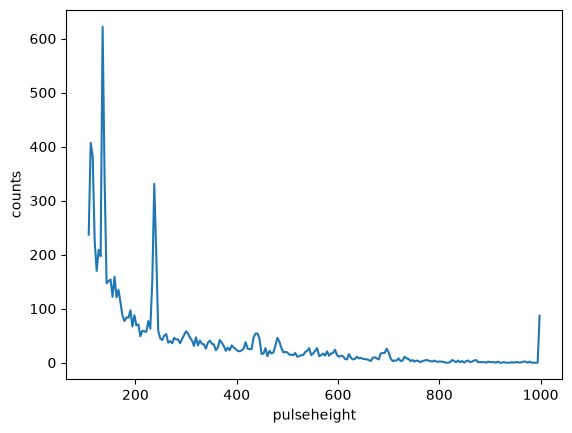

In [54]:
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()

In [55]:
def lorentzian(x, x0, a, gam ):
  return a * gam**2 / ( gam**2 + ( x - x0 )**2)

def multiple_lorentzian(x, x01, a1, gam1, x02, a2, gam2, x03, a3, gam3, x04, a4, gam4):
    return lorentzian(x, x01, a1, gam1) + lorentzian(x, x02, a2, gam2) + lorentzian(x, x03, a3, gam3) + lorentzian(x, x04, a4, gam4)

In [56]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=pulseheight, x01=100, a1=400, gam1=10, x02=150, a2=600, gam2=25, x03=220, a3=320, gam3=25, x04=100, a4=400, gam4=10)

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 9457
    # data points      = 228
    # variables        = 12
    chi-square         = 28705.5192
    reduced chi-square = 132.895922
    Akaike info crit   = 1126.49379
    Bayesian info crit = 1167.64593
    R-squared          = 0.97610375
[[Variables]]
    x01:   113.663749 +/- 0.09101743 (0.08%) (init = 100)
    a1:    455.302534 +/- 354.419572 (77.84%) (init = 400)
    gam1:  1.76053443 +/- 1.39112894 (79.02%) (init = 10)
    x02:   136.783642 +/- 0.15046816 (0.11%) (init = 150)
    a2:    3036.89850 +/- 8592.83887 (282.95%) (init = 600)
    gam2:  0.63902638 +/- 1.01148750 (158.29%) (init = 25)
    x03:   238.410793 +/- 0.19123529 (0.08%) (init = 220)
    a3:    351.312121 +/- 50.5357121 (14.38%) (init = 320)
    gam3:  2.16706553 +/- 0.35246936 (16.26%) (init = 25)
    x04:  -46.2478298 +/- 61.0566238 (132.02%) (init = 100)
    a4:    1609441.83 +/- 8.9739e+09 (5

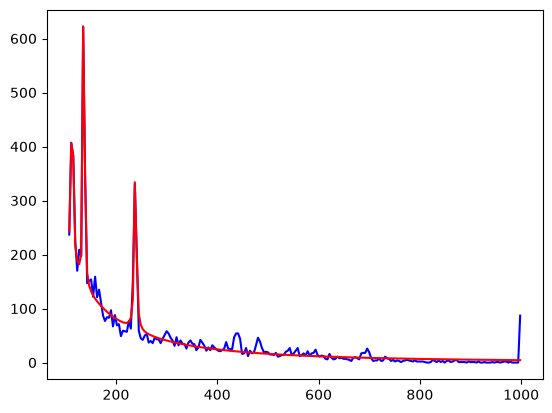

In [57]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [58]:
pulseheight1 = fit_result.params['x01'].value
pulseheight2 = fit_result.params['x02'].value
pulseheight3 = fit_result.params['x03'].value
pulseheight4 = fit_result.params['x04'].value

err_1 = fit_result.params['x01'].stderr
err_2 = fit_result.params['x02'].stderr
err_3 = fit_result.params['x03'].stderr
err_4 = fit_result.params['x04'].stderr

print(pulseheight1, err_1)
print(pulseheight2, err_2)
print(pulseheight3, err_3)
print(pulseheight4, err_4)

113.66374931904362 0.09101742835451322
136.78364229921436 0.1504681565695766
238.4107930457584 0.19123529280823795
-46.24782981606641 61.05662378449796


In [ ]:
def h_to_E(x):
    y = 2.98359957 * x - 65.6423766
    return y

E_1 = h_to_E(pulseheight1)
E_2 = h_to_E(pulseheight2)
E_3 = h_to_E(pulseheight3)

err1 = h_to_E(err_1)
err2 = h_to_E(err_2)
err3 = h_to_E(err_3)

print(E_1, err1)
print(E_2, err2)
print(E_3, err3)

273.48473699288627 -65.37081703989898
342.4652397469698 -65.19343987276032
645.6799630146837 -65.07180706260853
